# 01 · 从结构到数据空间
**DP-EVA 实验课堂 · 约 5 分钟**

这一节的问题：**30,656 个结构，怎样理解哪些已经相似、哪些值得保留？**

使用论文的 Fe–C–H–O 数据与 DPA3 特征。每帧代表一个原子构型，737 个 DeepMD system 按组成组织，并非 737 条独立轨迹。能量、力和 virial 均已有 ABACUS 标签。

本节可独立运行。先执行全部单元格，再使用末尾控件查看结构。


## 先用一分钟看懂 DP-EVA
铁基费托合成（FTS）把 CO 与 H₂ 转化为燃料和化学品。面向这一过程的势模型需要同时描述体相、表面和吸附物；候选结构很多，其中既有相似构型，也有模型尚未学好的环境。

**DP-EVA 用预训练知识回答两个选数问题：哪些值得学习，哪些具有代表性？**

| 预训练知识的用途 | 方法 | 对应章节 |
|---|---|---|
| 解码器的预测提供模型信息 | 浅层委员会 + 双指标 UQ，筛出值得补充学习的候选 | 03 |
| 编码器的表示组织结构空间 | DIRECT 选择代表；joint-DIRECT 同时考虑已有训练集 | 01–03 |
| 用选定数据构建领域模型 | 标注、正式微调、验证误差与应用测试 | 04 |

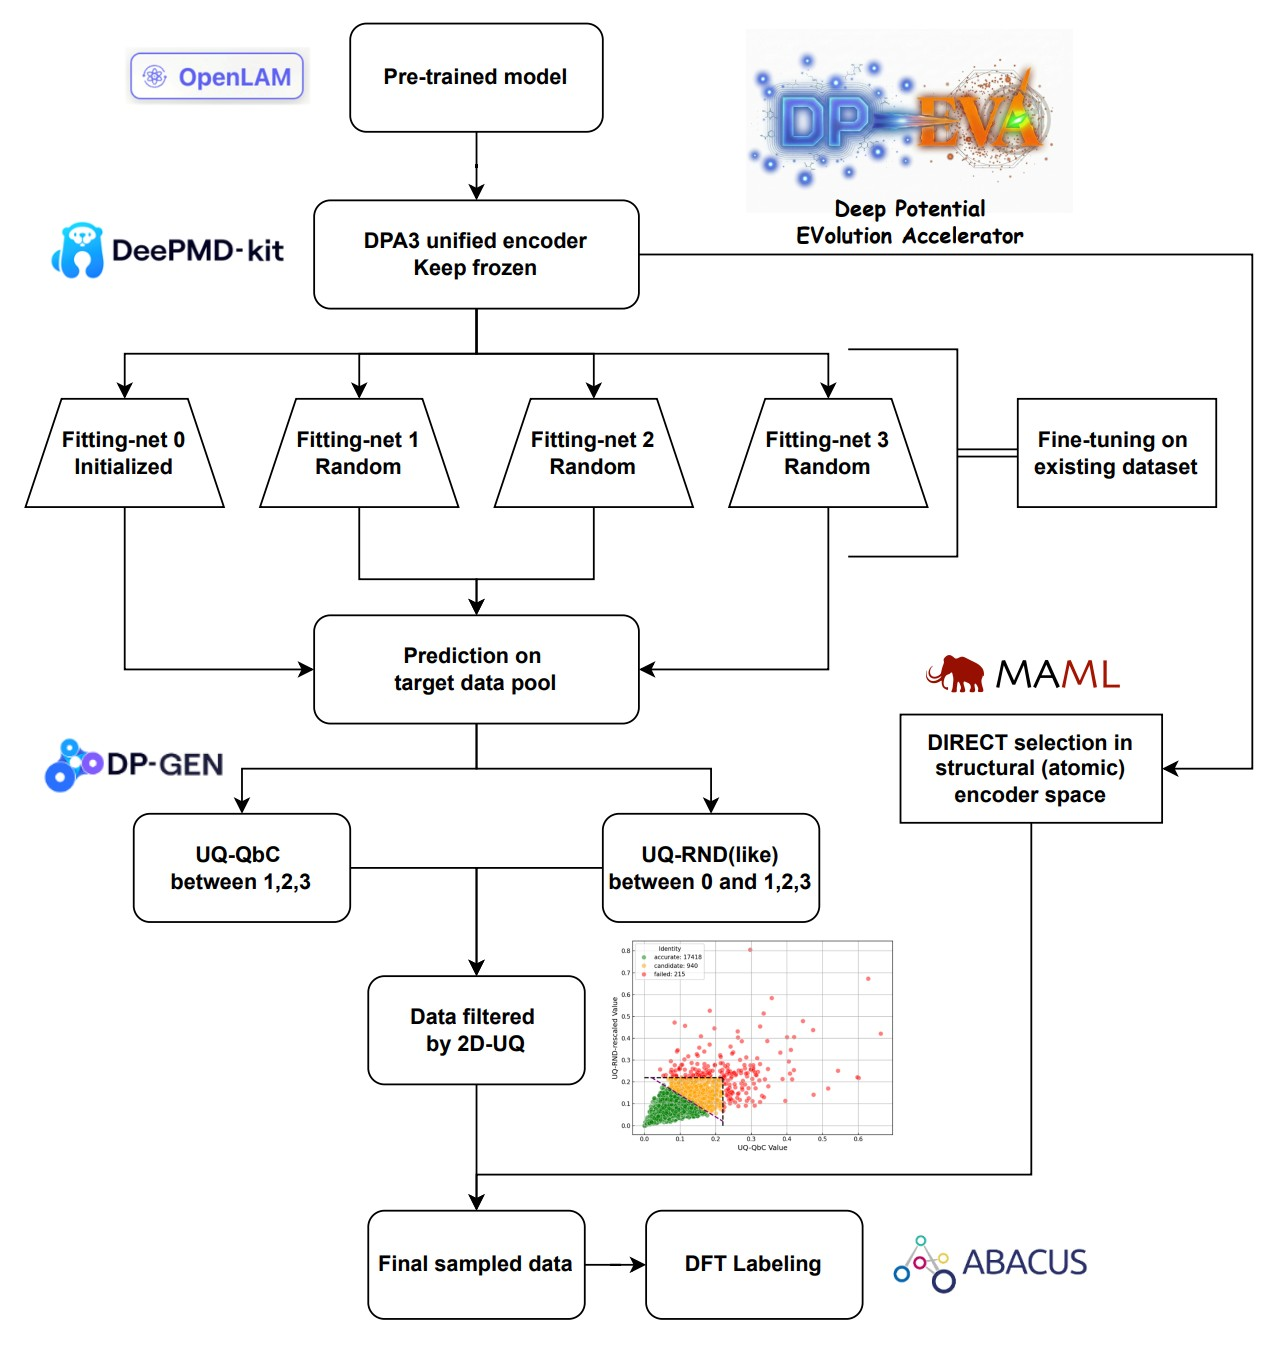

**论文图 1｜两条方法线汇合到数据选择。** 阅读时先沿左侧“浅层模型 → 预测 → UQ”，再沿右侧“编码器 → DIRECT”；下方连接标注。图中小散点图是原论文示意，课堂的全量统计见第 03 章。来源：Liu 等，DP-EVA，Figure 1；作者提供的 JPG 版本，CC BY-NC 4.0，未改绘。详见 [图片来源](figures/README.md)。

本案例从已有、已标注的完整数据集中隐藏答案后选数，检验能否减少微调所需数据。真实新任务中，候选通常来自模拟或结构搜索，选中后再做 DFT。框架图中的冻结编码器用于筛选模型；最终应用模型的训练设置见第 03 章。背景可读 [FT²DP 原文](https://www.oaepublish.com/articles/jmi.2024.105)，方法对应 [DP-EVA 论文](https://doi.org/10.1093/ce/zkag029)。


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
candidates = [Path.cwd(), Path.cwd() / 'examples/tutorials/paper_case']
TUTORIAL = next((p.resolve() for p in candidates if (p / 'tutorial_support.py').is_file()), None)
if TUTORIAL is None:
    raise RuntimeError('请从仓库根目录或 paper_case 目录启动 Jupyter。')
sys.path.insert(0, str(TUTORIAL))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
import tutorial_support as t
bundle = t.load_bundle()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15})
print('DP-EVA 源码: 当前仓库 src/dpeva')
print('模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU')


DP-EVA 源码: 当前仓库 src/dpeva
模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU


In [2]:
manifest = bundle['manifest']
summary = pd.Series({'总帧数': len(manifest), '初始训练帧数': (manifest.role == 'train').sum(),
                     '候选池帧数': (manifest.role == 'pool').sum(),
                     '最少原子数': manifest.n_atoms.min(), '原子数中位数': manifest.n_atoms.median(),
                     '最多原子数': manifest.n_atoms.max(), '特征维度': bundle['features'].shape[1]})
display(summary.to_frame('数量'))
display(manifest[['frame_id', 'source_dataname', 'role', 'Fe', 'C', 'H', 'O', 'n_atoms']].head())


,数量
总帧数,30656.0
初始训练帧数,3000.0
候选池帧数,27656.0
最少原子数,15.0
原子数中位数,29.0
最多原子数,329.0
特征维度,128.0


,frame_id,source_dataname,role,Fe,C,H,O,n_atoms
0,train/C13Fe28H2O1-124,C13Fe28H2O1-124,train,28,13,2,1,44
1,train/C3Fe26H2O2-7,C3Fe26H2O2-7,train,26,3,2,2,33
2,train/C14Fe35H6O1-84,C14Fe35H6O1-84,train,35,14,6,1,56
3,train/C13Fe17H9O0-2,C13Fe17H9O0-2,train,17,13,9,0,39
4,train/C0Fe12H19O0-19,C0Fe12H19O0-19,train,12,0,19,0,31


## 先看组成和大小
不是每个构型都含有四种元素。下图的元素比例是**按原子计数**，原子数分布则是**按帧计数**。这两个统计不能混用。

`frame_id` 带有 train/pool 命名空间；同一组成下的帧号在不同数据目录中可能已重新编号。


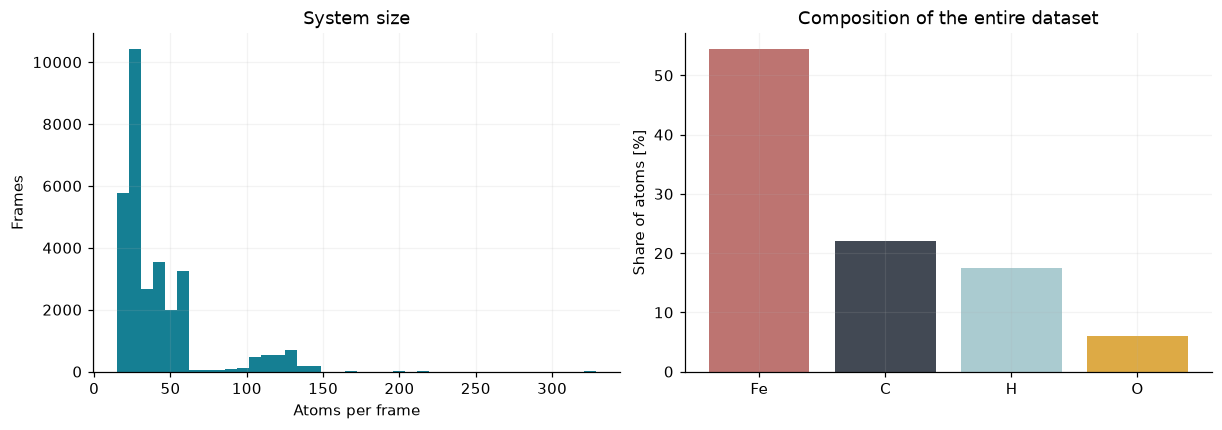

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
manifest.n_atoms.hist(bins=40, ax=axes[0], color='#157f93')
axes[0].set(xlabel='Atoms per frame', ylabel='Frames', title='System size')
counts = manifest[['Fe','C','H','O']].sum()
axes[1].bar(counts.index, counts / counts.sum() * 100, color=['#bd7471','#424954','#aacbd0','#ddaa45'])
axes[1].set(ylabel='Share of atoms [%]', title='Composition of the entire dataset')
plt.show()


**图 1｜数据集的大小与组成。** 左图统计每帧的原子数，右图统计全体原子中各元素的比例。来源：本目录真实结构索引；现场计算。

## 特征是如何得到的？
DPA3 为每个原子生成 128 维描述符。论文对一帧内的原子特征做均值池化，再做 L2 归一化。

下面对全部 30,656 帧做标准化和二维 PCA，**只用于观察分布**。后面 DIRECT 使用 Kaiser 规则保留的多维主成分，不能用这两个坐标替代原始特征。

绿色点表示论文冷启动选中的 3,000 帧；背景为剩余 27,656 帧。


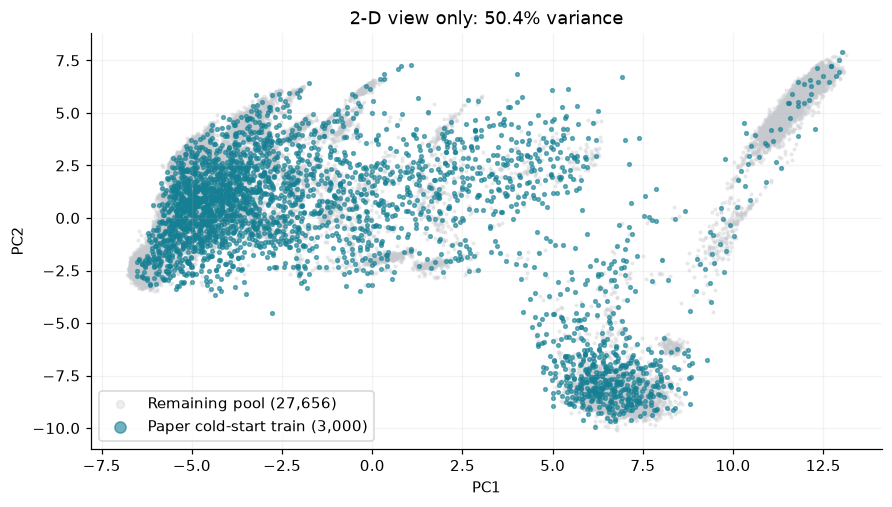

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
scaled = StandardScaler().fit_transform(bundle['features'])
view_pca = PCA(n_components=2, svd_solver='full')
xy = view_pca.fit_transform(scaled)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.scatter(xy[3000:, 0], xy[3000:, 1], s=3, c='#c6c9ce', alpha=.3, label='Remaining pool (27,656)')
ax.scatter(xy[:3000, 0], xy[:3000, 1], s=6, c='#157f93', alpha=.6, label='Paper cold-start train (3,000)')
ax.set(xlabel='PC1', ylabel='PC2', title=f'2-D view only: {view_pca.explained_variance_ratio_.sum():.1%} variance')
ax.legend(markerscale=3)
plt.show()


**图 2｜全量特征的二维投影。** 绿色为论文初始训练集，灰色为剩余池。二维投影用于观察整体分布，实际采样使用多维特征。来源：归档 DPA3 描述符；现场计算 PCA。

## 看一个真实结构
教学包已包含全部 30,656 帧的坐标、晶胞与 DFT 标签，可查看训练集及候选池中的任意一帧。每帧均已核对原始编号、划分身份与描述符；`source_dataname` 给出完整原数据中的编号。

框线为晶胞；所有结构来自周期性 DeepMD 数据。仅绘图，不启动桌面 GUI。


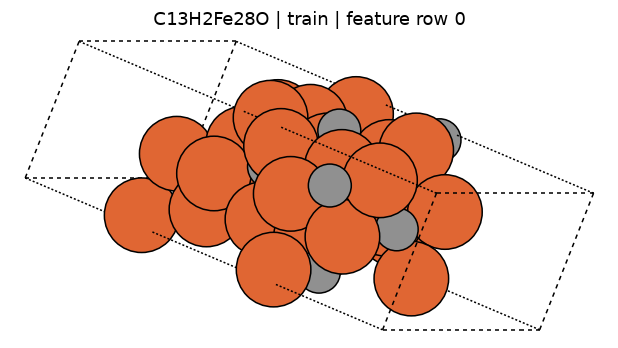

C13Fe28H2O1-124


In [5]:
print(t.show_structure(0))
widgets.interact(t.show_structure, feature_row=widgets.IntSlider(value=0, min=0, max=30655, description='结构编号', continuous_update=False));


**图 3｜论文数据中的真实原子结构。** 球表示原子，框线表示周期晶胞；可拖动控件切换结构。来源：教学包 `structures.npz`，由 ASE 绘制。

**讨论**：二维图中很近的两个点一定是相似结构吗？

下一步：在同一份特征上改变采样预算，看覆盖变化。实时练习默认使用全量数据；也可切换到固定的 768 帧小切片。重点观察所选结构对数据空间的代表性。
